# Day 41: SNR Evaluation of DAS Reconstruction

## Objective
Evaluate reconstructed image quality using SNR relative
to a full-array DAS reference image.

## Methods
- Incomplete sensor array
- Linear interpolation
- Cubic spline interpolation

## Reference
Full-array DAS reconstruction from synthetic sensor signals.

Reference image shape: (100, 100)

Reference-based SNR results:
incomplete: 12.0269 dB
linear_interpolation: 49.8752 dB
cubic_spline_interpolation: 64.7739 dB


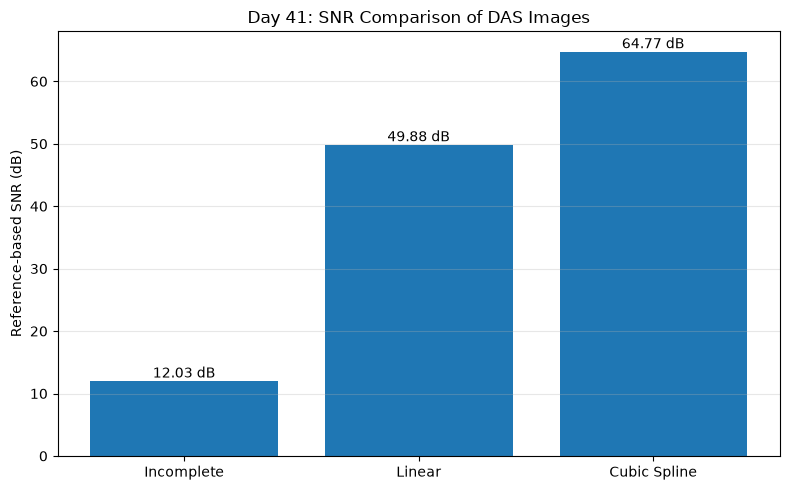


Results saved to: ..\outputs\day41_snr_results.json
{
    "day": 41,
    "metric": "Reference-based SNR",
    "num_sensors": 32,
    "num_inactive_sensors": 8,
    "dropout_fraction": 0.25,
    "inactive_sensor_indices_zero_based": [
        1,
        5,
        9,
        13,
        17,
        21,
        25,
        29
    ],
    "reference": "Full-array DAS image from synthetic signals; not physical ground truth",
    "definition": "10 * log10(sum(reference**2) / sum((reference - estimate)**2))",
    "results": {
        "incomplete": {
            "SNR_dB": 12.02691522999852,
            "signal_power": 1139195.168441126,
            "error_power": 71434.27006775684
        },
        "linear_interpolation": {
            "SNR_dB": 49.87516375168656,
            "signal_power": 1139195.168441126,
            "error_power": 11.724160608989203
        },
        "cubic_spline_interpolation": {
            "SNR_dB": 64.7738669231756,
            "signal_power": 1139195.168441126,


In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, CubicSpline

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
num_sensors = 32
num_samples = 600
fs = 10e6
c = 1500.0

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)
sensor_y = np.zeros(num_sensors)
time = np.arange(num_samples) / fs

x_grid = np.linspace(-10e-3, 10e-3, 100)
y_grid = np.linspace(2e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Generate synthetic sensor signals
# --------------------------------------------------
signals_full = np.zeros((num_sensors, num_samples))

for i in range(num_sensors):
    distance = np.sqrt(
        (sensor_x[i] - source_x) ** 2
        + (sensor_y[i] - source_y) ** 2
    )

    arrival_time = distance / c

    signals_full[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width) ** 2
    )

# --------------------------------------------------
# 3. Simulate 25% sensor dropout
# --------------------------------------------------
missing_indices = np.array([1, 5, 9, 13, 17, 21, 25, 29])

sensor_mask = np.ones(num_sensors, dtype=bool)
sensor_mask[missing_indices] = False

signals_missing = signals_full.copy()
signals_missing[~sensor_mask, :] = 0.0

# --------------------------------------------------
# 4. Reconstruct missing sensor signals
# --------------------------------------------------
known_x = sensor_x[sensor_mask]
known_signals = signals_full[sensor_mask, :]

linear_interpolator = interp1d(
    known_x,
    known_signals,
    axis=0,
    kind="linear",
    bounds_error=False,
    fill_value="extrapolate"
)

signals_linear = signals_missing.copy()
signals_linear[~sensor_mask, :] = linear_interpolator(
    sensor_x[~sensor_mask]
)

spline_interpolator = CubicSpline(
    known_x,
    known_signals,
    axis=0,
    bc_type="natural",
    extrapolate=True
)

signals_spline = signals_missing.copy()
signals_spline[~sensor_mask, :] = spline_interpolator(
    sensor_x[~sensor_mask]
)

# --------------------------------------------------
# 5. Delay-and-Sum reconstruction
# --------------------------------------------------
def das_reconstruction(signals):
    image = np.zeros_like(X, dtype=float)

    for i in range(num_sensors):
        distance_map = np.sqrt(
            (X - sensor_x[i]) ** 2
            + (Y - sensor_y[i]) ** 2
        )

        travel_time_map = distance_map / c

        delayed_values = np.interp(
            travel_time_map.ravel(),
            time,
            signals[i],
            left=0.0,
            right=0.0
        ).reshape(X.shape)

        image += delayed_values

    return image


image_reference = das_reconstruction(signals_full)
image_missing = das_reconstruction(signals_missing)
image_linear = das_reconstruction(signals_linear)
image_spline = das_reconstruction(signals_spline)

print("Reference image shape:", image_reference.shape)

# --------------------------------------------------
# 6. Calculate reference-based SNR
# --------------------------------------------------
def calculate_reference_snr(reference, estimate):
    """
    Calculate SNR relative to a reference image.

    Signal power = sum(reference ** 2)
    Error power  = sum((reference - estimate) ** 2)

    This is a reference-based reconstruction metric,
    not a measurement of physical acquisition noise.
    """
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)

    if reference.shape != estimate.shape:
        raise ValueError("Reference and estimate shapes must match.")

    signal_power = float(np.sum(reference ** 2))
    error_power = float(np.sum((reference - estimate) ** 2))

    if signal_power == 0:
        raise ValueError("Reference image has zero signal power.")

    if error_power == 0:
        snr_db = float("inf")
    else:
        snr_db = float(10 * np.log10(signal_power / error_power))

    return {
        "SNR_dB": snr_db,
        "signal_power": signal_power,
        "error_power": error_power
    }


snr_results = {
    "incomplete": calculate_reference_snr(
        image_reference, image_missing
    ),
    "linear_interpolation": calculate_reference_snr(
        image_reference, image_linear
    ),
    "cubic_spline_interpolation": calculate_reference_snr(
        image_reference, image_spline
    )
}

print("\nReference-based SNR results:")
for method, result in snr_results.items():
    print(f"{method}: {result['SNR_dB']:.4f} dB")

# --------------------------------------------------
# 7. Plot SNR comparison
# --------------------------------------------------
methods = ["Incomplete", "Linear", "Cubic Spline"]
snr_values = [
    snr_results["incomplete"]["SNR_dB"],
    snr_results["linear_interpolation"]["SNR_dB"],
    snr_results["cubic_spline_interpolation"]["SNR_dB"]
]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, snr_values)

plt.ylabel("Reference-based SNR (dB)")
plt.title("Day 41: SNR Comparison of DAS Images")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, snr_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f} dB",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    output_dir / "day41_snr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 8. Save numerical results
# --------------------------------------------------
results = {
    "day": 41,
    "metric": "Reference-based SNR",
    "num_sensors": int(num_sensors),
    "num_inactive_sensors": int(len(missing_indices)),
    "dropout_fraction": float(len(missing_indices) / num_sensors),
    "inactive_sensor_indices_zero_based": missing_indices.tolist(),
    "reference": (
        "Full-array DAS image from synthetic signals; "
        "not physical ground truth"
    ),
    "definition": (
        "10 * log10(sum(reference**2) / "
        "sum((reference - estimate)**2))"
    ),
    "results": snr_results,
    "output_plot": "day41_snr_comparison.png"
}

results_path = output_dir / "day41_snr_results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("\nResults saved to:", results_path)
print(json.dumps(results, indent=4, ensure_ascii=False))